# Figures and numbers for *Capillary effects on the self-similar growth of immiscible Rayleigh–Taylor mixing*

M. D. Walker and S. S. Nixon, submitted to *Journal of Fluid Mechanics* (Rapids).

This notebook reproduces every figure of the paper and the figures of its supplementary material that are computed
from the simulations, and prints the numbers quoted in the text. The simulations are the immiscible Rayleigh–Taylor simulations of
Walker *et al.* (2025, 2026, 2027*a*,*b*) at $\mathrm{A_t} = 0.5$ with $1120^3$ points. They were presented at the 78th Annual Meeting of the APS Division of Fluid Dynamics ([abstract](https://meetings-archive.aps.org/dfd/2025/u30/8/), [talk](https://drive.google.com/file/d/1jgFE_YQC5uhCAsLqNTcmoPDsvbyvzH8O/view?usp=sharing)) and at IWPCTM19 ([abstract](https://drive.google.com/file/d/16irNsqovxGmB08cWheF4SVbzx0tQUwVy/view?usp=sharing), [talk](https://drive.google.com/file/d/1QZafiOuN54a5-OdcKpDUJfjF_emxIF6a/view?usp=sharing)). Their curves are in `data/`,
extracted from the vector figures in `figures/simulations/` (section 1). Every figure is written to `figures/` as a PDF
and a PNG.

| Section | Output in `figures/` | In the paper |
|---|---|---|
| 2 | `fig_alpha_time`, `fig_alpha_height` | figure 1(*a*), (*b*) |
| 3 | `fig_capillary_group`, `fig_nu_Ds` | figure 2(*a*), (*b*) |
| 4 | `fig_excess_width`, `fig_We_exponent`; the fit $\alpha - \alpha_{\mathrm{We}_0=\infty} \approx 8.9\,\ell_\sigma/h$; table S2 | figure 3(*a*), (*b*) |
| 5 | `fig_hinze_ratio`; $K_H$ | figure S1 |
| 6 | `fig_transition_time`, `fig_alpha_transition`; transition-time fits | figure S4 |
| 7 | `fig_Rf_time`; table S3 | figure S5, table S3 |

In [1]:
%matplotlib inline
import csv, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import style

style.use('classic')

DATA_DIR = 'data'
FIG_DIR = 'figures'
SIM_DIR = os.path.join(FIG_DIR, 'simulations')
PNG_DPI = 200
REEXTRACT = False      # True: re-read the curves from the vector figures in figures/simulations/ (needs PyMuPDF)

AT = 0.5                                  # Atwood number
LAMBDA0, DX = 1.02e-2, 1.14e-3            # initial wavelength lambda_0 = L/k_max and grid spacing [m]
WE = {'We50': 50.0, 'We100': 100.0, 'We200': 200.0, 'We_inf': np.inf}
FIN = ['We50', 'We100', 'We200']
LABELS = {'We50': r'$\mathrm{We}_0=50$', 'We100': r'$\mathrm{We}_0=100$', 'We200': r'$\mathrm{We}_0=200$',
          'We_inf': r'$\mathrm{We}_0=\infty$'}
COLORS = {'We50': 'tab:blue', 'We100': 'tab:orange', 'We200': 'tab:green', 'We_inf': 'tab:red'}
BOX = dict(boxstyle='square,pad=0.02', fc='white', ec='none', alpha=0.8)
ARROW = dict(facecolor='black', edgecolor='none', shrink=0.05, width=3, headwidth=10)
os.makedirs(FIG_DIR, exist_ok=True)


def text_box(ax, lines=('3-D', r'$N_{\mathrm{pts}} = 1120$', r'$\mathrm{A_t} = 0.5$', r'$\mathrm{Re}_0 = \infty$'),
             loc=(0.8, 0.97)):
    ax.text(loc[0], loc[1], '\n'.join(lines), transform=ax.transAxes, fontsize=20, verticalalignment='top',
            bbox=dict(boxstyle='square,pad=0.2', fc='white', ec='none', alpha=0.8))


def finish(ax, name, legend_loc='best', fontsize=16):
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.2)
    ax.legend(loc=legend_loc, fontsize=fontsize, numpoints=1)
    plt.savefig(os.path.join(FIG_DIR, f'{name}.pdf'), bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), bbox_inches='tight', dpi=PNG_DPI)
    plt.show()
    plt.close()

## 1. Data

Each file in `data/` holds one quantity in long format, `case,t_over_tau0,<quantity>`, for the cases `We50`, `We100`,
`We200`, `We_inf` and `miscible`; `transition_times.csv` holds $t_\theta/\tau_0$, the time of maximum
$d\overline{\theta}/dt$. The README describes the columns.

The curves were extracted from the vector paths of the figures in `figures/simulations/`. Matplotlib writes each line
in a PDF as a path, a list of segment endpoints in page coordinates with its colour, width and dash pattern, and the
tick labels as text with their positions. The extraction

1. reads the paths with PyMuPDF;
2. keeps the solid width-3 curves, identified by colour, and drops anything inside the legend box;
3. records the coloured dashed vertical lines, which mark $t_\theta$;
4. maps page coordinates to data coordinates with a linear fit to the tick-label positions (on a logarithmic axis, to
   the exponents of its $10^{-n}$ labels, whose minus sign is drawn as a path).

The immiscible cases are taken from the `immiscible_*` figures and the miscible case from the `alpha_time_misc_imm_*`
figures. The next cell runs only if `REEXTRACT = True` or a data file is missing.

In [2]:
SOURCES = {   # data file: (immiscible figure, miscible figure, column, logarithmic y axis)
    'growth_parameter.csv': ('immiscible_alpha_time', 'alpha_time_misc_imm', 'alpha', False),
    'mixing_width.csv': ('immiscible_alpha_time_height', 'alpha_time_misc_imm_height', 'h_over_lambda0', False),
    'growth_velocity.csv': ('immiscible_alpha_time_velocity', 'alpha_time_misc_imm_velocity', 'hdot_norm', False),
    'midplane_mass_flux.csv': ('immiscible_alpha_time_mass_flux', 'alpha_time_misc_imm_mass_flux', 'mass_flux_norm', False),
    'midplane_rho_rms.csv': ('immiscible_alpha_time_rho_rms', 'alpha_time_misc_imm_rho_rms', 'rho_rms_norm', False),
    'midplane_w_rms.csv': ('immiscible_alpha_time_w_rms', 'alpha_time_misc_imm_w_rms', 'w_rms_norm', False),
    'scaling_ratio.csv': ('immiscible_alpha_time_flux_ratio', 'alpha_time_misc_imm_flux_ratio', 'scaling_ratio', False),
    'hinze_scale.csv': ('immiscible_integral_TKE_hinze_scale', None, 'l_H_m', True),
}
PDF_COLORS = {'We50': (0.122, 0.467, 0.706), 'We100': (1.0, 0.498, 0.055), 'We200': (0.173, 0.627, 0.173),
              'We_inf': (0.839, 0.153, 0.157), 'black': (0.0, 0.0, 0.0)}
GRID_T = {0.0, 2.0, 4.0, 6.0, 8.0, 10.0}   # black dashed vertical grid lines, not transition markers


def _close(c1, c2, tol=0.02):
    return c1 is not None and all(abs(a - b) < tol for a, b in zip(c1, c2))


def _num(s):
    try:
        return float(s.replace('−', '-'))
    except ValueError:
        return None


def extract_curves(path):
    """Curves and dashed vertical markers of a figure with linear axes."""
    import fitz  # PyMuPDF
    pg = fitz.open(path)[0]
    dr = pg.get_drawings()
    frame = [p['rect'] for p in dr if _close(p.get('color'), (0, 0, 0), 1e-3)
             and abs((p.get('width') or 0) - 1.0) < 1e-3 and len(p['items']) == 1]
    xs = sorted({round(r.x0, 2) for r in frame if abs(r.x0 - r.x1) < 1e-3})
    ys = sorted({round(r.y0, 2) for r in frame if abs(r.y0 - r.y1) < 1e-3})
    x0, x1, y0, y1 = xs[0], xs[-1], ys[0], ys[-1]
    legend = [p['rect'] for p in dr if _close(p.get('color'), (0, 0, 0), 1e-3)
              and abs((p.get('width') or 0) - 1.0) < 1e-3 and p['rect'].width > 5 and p['rect'].height > 5]
    xt, yt = [], []
    for w in pg.get_text('words'):
        v = _num(w[4])
        if v is None:
            continue
        cx, cy = 0.5 * (w[0] + w[2]), 0.5 * (w[1] + w[3])
        if y1 - 3 <= w[1] < y1 + 25 and x0 - 10 <= cx <= x1 + 10:
            xt.append((cx, v))
        elif x0 - 40 < w[2] <= x0 + 3 and y0 - 10 <= cy <= y1 + 10:
            yt.append((cy, v))
    xt, yt = np.array(xt), np.array(yt)
    px, py = np.polyfit(xt[:, 0], xt[:, 1], 1), np.polyfit(yt[:, 0], yt[:, 1], 1)
    curves, vlines = {}, {}
    for p in dr:
        name = next((k for k, c in PDF_COLORS.items() if _close(p.get('color'), c)), None)
        if name is None or any(lg.contains(p['rect']) for lg in legend):
            continue
        pts = []
        for it in p['items']:
            if it[0] == 'l':
                pts += [it[1], it[2]]
            elif it[0] == 'c':
                pts += [it[1], it[4]]
        if not pts:
            continue
        r = p['rect']
        if abs((p.get('width') or 0) - 3.0) < 1e-3 and p.get('dashes') in ('[] 0', None):
            curves.setdefault(name, []).append(np.array([[q.x, q.y] for q in pts]))
        if len(p['items']) == 1 and abs(r.x0 - r.x1) < 1e-3 and r.height > 5 and p.get('dashes') not in ('[] 0', None):
            vlines.setdefault(name, []).append(float(np.polyval(px, r.x0)))
    out = {'curves': {}, 'vlines': vlines}
    for k, arrs in curves.items():
        arr = np.vstack(arrs)
        t, v = np.polyval(px, arr[:, 0]), np.polyval(py, arr[:, 1])
        o = np.argsort(t, kind='stable'); t, v = t[o], v[o]
        keep = np.r_[True, np.diff(t) > 1e-6]
        out['curves'][k] = {'x': t[keep].tolist(), 'y': v[keep].tolist()}
    return out


def extract_curves_log(path, logy=False):
    """As extract_curves (curves only), also for a logarithmic y axis whose labels are 10^-n."""
    import fitz  # PyMuPDF
    pg = fitz.open(path)[0]
    dr = pg.get_drawings()
    frame = [p['rect'] for p in dr if _close(p.get('color'), (0, 0, 0), 1e-3)
             and abs((p.get('width') or 0) - 1.0) < 1e-3 and len(p['items']) == 1]
    xs = sorted({round(r.x0, 2) for r in frame if abs(r.x0 - r.x1) < 1e-3})
    ys = sorted({round(r.y0, 2) for r in frame if abs(r.y0 - r.y1) < 1e-3})
    x0, x1, y0, y1 = xs[0], xs[-1], ys[0], ys[-1]
    legend = [p['rect'] for p in dr if _close(p.get('color'), (0, 0, 0), 1e-3)
              and abs((p.get('width') or 0) - 1.0) < 1e-3 and p['rect'].width > 5 and p['rect'].height > 5
              and not (abs(p['rect'].x0 - x0) < 1 and abs(p['rect'].x1 - x1) < 1)]
    words = pg.get_text('words')
    xt, yt = [], []
    for w in words:
        v = _num(w[4]); cx, cy = 0.5 * (w[0] + w[2]), 0.5 * (w[1] + w[3])
        if v is not None and y1 - 3 <= w[1] < y1 + 25 and x0 - 10 <= cx <= x1 + 10:
            xt.append((cx, v))
        elif not logy and v is not None and x0 - 40 < w[2] <= x0 + 3 and y0 - 10 <= cy <= y1 + 10:
            yt.append((cy, v))
    if logy:
        for t in [w for w in words if w[4] == '10' and x0 - 45 < w[2] <= x0 + 3]:
            ex = [w for w in words if _num(w[4]) is not None and w[4] != '10' and 0 <= w[0] - t[2] < 10 and abs(w[1] - t[1]) < 3]
            if ex:
                yt.append((0.5 * (t[1] + t[3]), -abs(_num(ex[0][4]))))
    xt, yt = np.array(xt), np.array(yt)
    px, py = np.polyfit(xt[:, 0], xt[:, 1], 1), np.polyfit(yt[:, 0], yt[:, 1], 1)
    curves = {}
    for p in dr:
        name = next((k for k, c in PDF_COLORS.items() if _close(p.get('color'), c)), None)
        if name is None or any(lg.contains(p['rect']) for lg in legend):
            continue
        if not (abs((p.get('width') or 0) - 3.0) < 1e-3 and p.get('dashes') in ('[] 0', None)):
            continue
        pts = []
        for it in p['items']:
            if it[0] == 'l':
                pts += [it[1], it[2]]
            elif it[0] == 'c':
                pts += [it[1], it[4]]
        if pts:
            curves.setdefault(name, []).append(np.array([[q.x, q.y] for q in pts]))
    out = {}
    for k, arrs in curves.items():
        a = np.vstack(arrs)
        t, v = np.polyval(px, a[:, 0]), np.polyval(py, a[:, 1])
        if logy:
            v = 10 ** v
        o = np.argsort(t, kind='stable'); t, v = t[o], v[o]
        keep = np.r_[True, np.diff(t) > 1e-6]
        out[k] = {'x': t[keep].tolist(), 'y': v[keep].tolist()}
    return out


def write_curves(name, column, imm, mis=None):
    with open(os.path.join(DATA_DIR, name), 'w', newline='\n') as f:
        f.write(f'case,t_over_tau0,{column}\n')
        for k in [c for c in WE if c in imm]:
            f.writelines(f'{k},{x:.6g},{y:.6g}\n' for x, y in zip(imm[k]['x'], imm[k]['y']))
        if mis is not None:
            f.writelines(f'miscible,{x:.6g},{y:.6g}\n' for x, y in zip(mis['black']['x'], mis['black']['y']))


needed = list(SOURCES) + ['transition_times.csv']
if REEXTRACT or not all(os.path.exists(os.path.join(DATA_DIR, n)) for n in needed):
    os.makedirs(DATA_DIR, exist_ok=True)
    pdf = lambda n: os.path.join(SIM_DIR, n + '.pdf')
    for name, (imm, mis, column, logy) in SOURCES.items():
        if name in ('growth_parameter.csv', 'mixing_width.csv', 'growth_velocity.csv'):
            ci, cm = extract_curves(pdf(imm)), extract_curves(pdf(mis))
            write_curves(name, column, ci['curves'], cm['curves'])
            if name == 'mixing_width.csv':
                with open(os.path.join(DATA_DIR, 'transition_times.csv'), 'w', newline='\n') as f:
                    f.write('case,t_theta_over_tau0\n')
                    f.writelines(f'{k},{ci["vlines"][k][0]:.6g}\n' for k in WE)
                    t_mis = [t for t in cm['vlines']['black'] if round(t, 3) not in GRID_T]
                    f.write(f'miscible,{t_mis[0]:.6g}\n')
        else:
            write_curves(name, column, extract_curves_log(pdf(imm), logy),
                         None if mis is None else extract_curves_log(pdf(mis), logy))
    print('extracted', needed)
else:
    print('using the existing files in', DATA_DIR)

using the existing files in data


In [3]:
def read_curves(name):
    """{case: {'x': t/tau0, 'y': quantity}} from a long-format data file."""
    out = {}
    with open(os.path.join(DATA_DIR, name)) as f:
        rd = csv.reader(f)
        next(rd)
        for case, x, y in rd:
            c = out.setdefault(case, {'x': [], 'y': []})
            c['x'].append(float(x)); c['y'].append(float(y))
    return out


def curve(c, k):
    return np.array(c[k]['x']), np.array(c[k]['y'])


A = read_curves('growth_parameter.csv')          # alpha(t) = hdot^2 / 4 A_t g h
H = read_curves('mixing_width.csv')              # h/lambda_0
SR = read_curves('scaling_ratio.csv')            # hdot (rho_h - rho_l) / |rho'w'|_0 for the half-width; R_f = 2 x
RHO = read_curves('midplane_rho_rms.csv')        # rho'_rms / (rho_h - rho_l) on the mid-plane
HINZE = read_curves('hinze_scale.csv')           # l_H [m]
with open(os.path.join(DATA_DIR, 'transition_times.csv')) as f:
    T_THETA = {row['case']: float(row['t_theta_over_tau0']) for row in csv.DictReader(f)}


def alpha_of_h(k):
    # alpha and h/lambda0 on the alpha-curve time base
    ta, a = curve(A, k)
    th, h = curve(H, k)
    return ta, a, np.interp(ta, th, h)


t_peak = {k: float(curve(A, k)[0][np.argmax(curve(A, k)[1])]) for k in WE}
print('t_theta:', {k: round(v, 2) for k, v in T_THETA.items()})
print('t_peak :', {k: round(v, 2) for k, v in t_peak.items()})

t_theta: {'We50': 5.47, 'We100': 3.62, 'We200': 2.81, 'We_inf': 1.88, 'miscible': 2.14}
t_peak : {'We50': 4.03, 'We100': 2.38, 'We200': 1.73, 'We_inf': 1.3}


## 2. Figure 1: growth parameter

(*a*) $\alpha(t)$ for the four immiscible cases, with the miscible case for reference. (*b*) $\alpha$ against
$h/\lambda_0$ after the peak of $\alpha$. Here $h/\lambda_0$ is the mixing width of `mixing_width.csv`; it agrees with
$(\dot h/\sqrt{\mathrm{A_t} g\lambda_0})^2/4\alpha$ to within about 5 %.

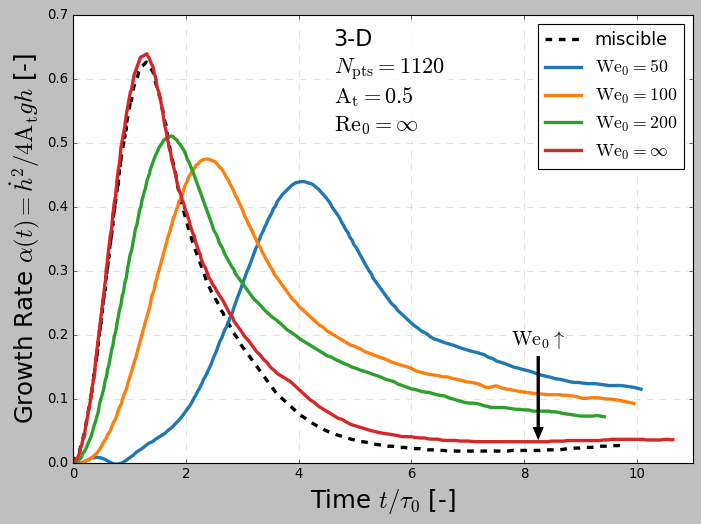

In [4]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
tm, am = curve(A, 'miscible')
ax.plot(tm, am, lw=3, color='black', linestyle='--', label='miscible')
for k in WE:
    t, a = curve(A, k)
    ax.plot(t, a, lw=3, color=COLORS[k], label=LABELS[k])
ax.annotate(r'$\mathrm{We}_0 \uparrow$', xy=(0.75, 0.04), xytext=(0.75, 0.25), xycoords='axes fraction',
            textcoords='axes fraction', ha='center', va='bottom', fontsize=18, arrowprops=ARROW, bbox=BOX)
ax.set_xlabel(r'Time $t/\tau_0$ [-]', fontsize=22)
ax.set_ylabel(r'Growth Rate $\alpha(t) = \dot{h}^2 / 4 \mathrm{A_t} g h$ [-]', fontsize=22)
ax.set_xlim(0, 11); ax.set_ylim(0, 0.7)
text_box(ax, loc=(0.42, 0.97))
finish(ax, 'fig_alpha_time', legend_loc='upper right')

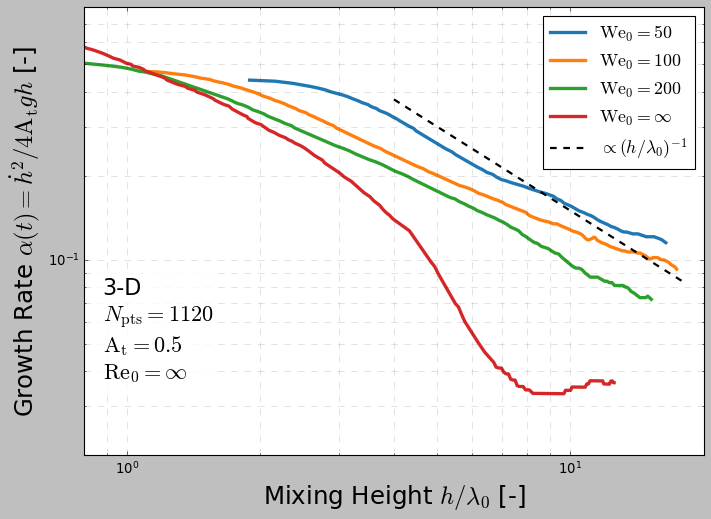

In [5]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
for k in WE:
    t, a, h = alpha_of_h(k)
    m = t > t_peak[k]
    ax.plot(h[m], a[m], lw=3, color=COLORS[k], label=LABELS[k])
hh = np.array([4, 18]); ax.plot(hh, 1.5 / hh, color='black', lw=2, linestyle='--', label=r'$\propto (h/\lambda_0)^{-1}$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'Mixing Height $h/\lambda_0$ [-]', fontsize=22)
ax.set_ylabel(r'Growth Rate $\alpha(t) = \dot{h}^2 / 4 \mathrm{A_t} g h$ [-]', fontsize=22)
ax.set_xlim(0.8, 20); ax.set_ylim(0.02, 0.8)
text_box(ax, loc=(0.03, 0.40))
finish(ax, 'fig_alpha_height', legend_loc='upper right')

## 3. Figure 2: capillary group and the exponent $\nu$

(*a*) The capillary group $d_\sigma \sim 1/\mathrm{We}(t) = \sigma/\bar\rho \dot h^2 h = 1/[4 \mathrm{A_t} \alpha \mathrm{We}_0 (h/\lambda_0)^2]$.
(*b*) The exponent $\nu$ in $(\ell_\sigma/h)^\nu$ from complete self-similarity, the Hinze-scale estimate and the
spectral closure, against the interface fractal dimension $D_s$ (theory only).

We50: 1/We(t) at t = 10.1: 3.2e-04
We100: 1/We(t) at t = 10.0: 1.8e-04
We200: 1/We(t) at t = 9.4: 1.5e-04


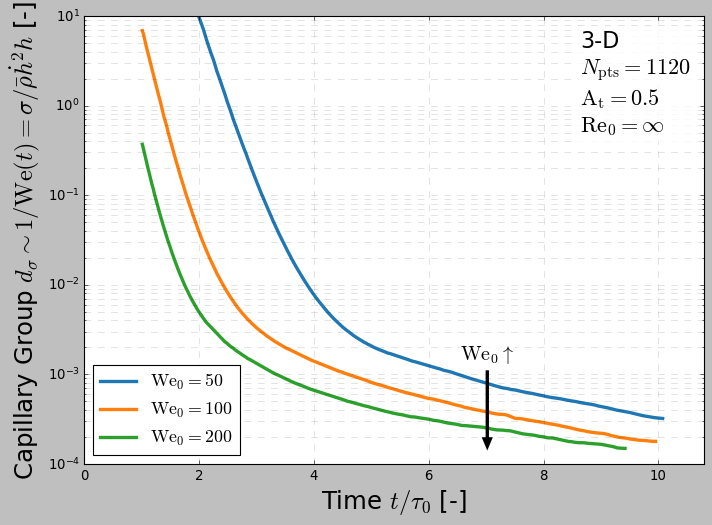

In [6]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
for k in FIN:
    t, a, h = alpha_of_h(k)
    m = t > 1.0
    We_t = 4 * a[m] * AT * WE[k] * h[m] ** 2
    ax.plot(t[m], 1 / We_t, lw=3, color=COLORS[k], label=LABELS[k])
    print(f'{k}: 1/We(t) at t = {t[m][-1]:.1f}: {1 / We_t[-1]:.1e}')
ax.set_yscale('log')
ax.set_xlabel(r'Time $t/\tau_0$ [-]', fontsize=22)
ax.set_ylabel(r'Capillary Group $d_\sigma \sim 1/\mathrm{We}(t) = \sigma / \bar{\rho} \dot{h}^2 h$ [-]', fontsize=22)
ax.set_xlim(0, 10.8); ax.set_ylim(1e-4, 10)
ax.annotate(r'$\mathrm{We}_0 \uparrow$', xy=(0.65, 0.02), xytext=(0.65, 0.22), xycoords='axes fraction',
            textcoords='axes fraction', ha='center', va='bottom', fontsize=18, arrowprops=ARROW, bbox=BOX)
text_box(ax)
finish(ax, 'fig_capillary_group', legend_loc='lower left')

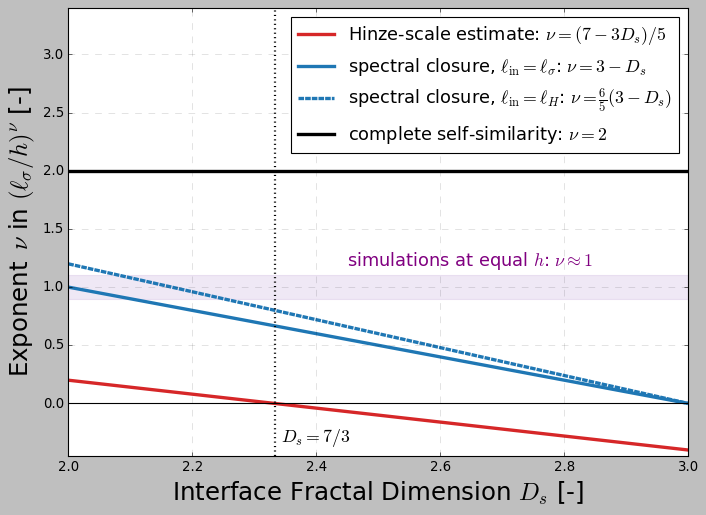

In [7]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
Ds = np.linspace(2, 3, 101)
ax.plot(Ds, (7 - 3 * Ds) / 5, lw=3, color='tab:red', label=r'Hinze-scale estimate: $\nu = (7-3D_s)/5$')
ax.plot(Ds, 3 - Ds, lw=3, color='tab:blue', label=r'spectral closure, $\ell_\mathrm{in}=\ell_\sigma$: $\nu = 3-D_s$')
ax.plot(Ds, 1.2 * (3 - Ds), lw=3, color='tab:blue', linestyle=(0, (5, 1)),
        label=r'spectral closure, $\ell_\mathrm{in}=\ell_H$: $\nu = \frac{6}{5}(3-D_s)$')
ax.plot(Ds, 2 + 0 * Ds, lw=3, color='black', label=r'complete self-similarity: $\nu = 2$')
ax.axhspan(0.9, 1.1, color='tab:purple', alpha=0.15)
ax.text(2.45, 1.18, r'simulations at equal $h$: $\nu \approx 1$', fontsize=16, color='purple')
ax.axvline(7 / 3, color='black', lw=2, linestyle=':')
ax.text(7 / 3 + 0.01, -0.33, r'$D_s = 7/3$', fontsize=16, color='black')
ax.axhline(0, color='black', lw=1)
ax.set_xlabel(r'Interface Fractal Dimension $D_s$ [-]', fontsize=22)
ax.set_ylabel(r'Exponent $\, \nu$ in $(\ell_\sigma/h)^{\nu}$ [-]', fontsize=22)
ax.set_xlim(2, 3); ax.set_ylim(-0.45, 3.4)
finish(ax, 'fig_nu_Ds', legend_loc='upper right')

## 4. Figure 3: comparison at equal mixing width and at fixed time

(*a*) The excess over $\mathrm{We}_0 = \infty$, evaluated at equal $h$ once the $\mathrm{We}_0 = \infty$ case has
settled, against $\ell_\sigma/h$, with $\ell_\sigma/\lambda_0 = (2\mathrm{A_t}\mathrm{We}_0)^{-1/2}$. The printed $K$,
its range and the log-log slope are the fit $\alpha - \alpha_{\mathrm{We}_0=\infty} \approx 8.9\,\ell_\sigma/h$ of the paper.
(*b*) The effective exponent $m$ in $\alpha \propto \mathrm{We}_0^{-m}$, fitted over $\mathrm{We}_0 = 50, 100, 200$,
at fixed $t/\tau_0$, at fixed $h/\lambda_0$ and at fixed time since transition. The last cell prints table S2.

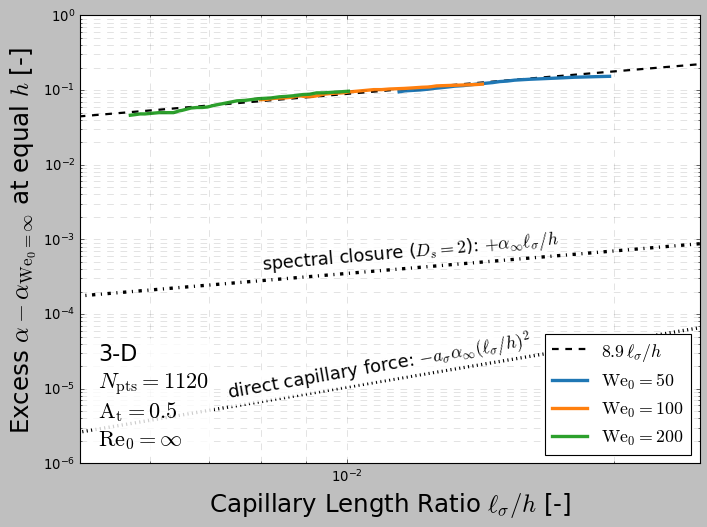

K = 8.89 (range 7.73-9.92), log-log slope 0.97, window 7.0 <= h/lambda0 <= 12.5


In [8]:
ti, ai, hi = alpha_of_h('We_inf')
mi = ti > t_peak['We_inf'] + 3.0       # after the sigma = 0 case has settled
HMIN, HMAX = 7.0, hi.max()
# excess at equal h for each finite-We0 case (computed first so the fit line can be drawn first)
excess = {}
for k in FIN:
    t, a, h = alpha_of_h(k)
    m = (h >= HMIN) & (h <= HMAX) & (t > t_peak[k])
    ainf = np.interp(h[m], hi[mi], ai[mi])
    excess[k] = ((2 * AT * WE[k]) ** -0.5 / h[m], a[m] - ainf)     # (l_sigma/h, alpha - alpha_inf)
allx = np.concatenate([v[0] for v in excess.values()]); ally = np.concatenate([v[1] for v in excess.values()])
K = np.exp(np.mean(np.log(ally / allx)))
slope = np.polyfit(np.log(allx), np.log(ally), 1)[0]
xs = np.logspace(np.log10(2e-3), np.log10(5e-2), 50)

plt.figure(figsize=(10, 7)); ax = plt.gca()
ax.plot(xs, K * xs, color='black', lw=2, linestyle='--', label=rf'${K:.1f}\,\ell_\sigma/h$')
for k in FIN:
    ax.plot(*excess[k], lw=3, color=COLORS[k], label=LABELS[k])
alpha_inf = 0.035
ax.plot(xs, alpha_inf * xs, color='black', lw=3, linestyle='-.')
ax.plot(xs, 3 * alpha_inf * xs ** 2, color='black', lw=3, linestyle=':')
ax.text(8e-3, 4e-4, r'spectral closure ($D_s=2$): $+\alpha_\infty \ell_\sigma/h$', fontsize=16,
        rotation=5, bbox=BOX)
ax.text(7.3e-3, 0.73e-5, r'direct capillary force: $-a_\sigma \alpha_\infty (\ell_\sigma/h)^2$', fontsize=16,
        rotation=10, bbox=BOX)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'Capillary Length Ratio $\ell_\sigma/h$ [-]', fontsize=22)
ax.set_ylabel(r'Excess $\alpha - \alpha_{\mathrm{We}_0=\infty}$ at equal $h$ [-]', fontsize=22)
ax.set_xlim(5e-3, 2.5e-2); ax.set_ylim(1e-6, 1)
text_box(ax, loc=(0.03, 0.27))
finish(ax, 'fig_excess_width', legend_loc='lower right')
print(f'K = {K:.2f} (range {np.min(ally/allx):.2f}-{np.max(ally/allx):.2f}), log-log slope {slope:.2f}, '
      f'window {HMIN} <= h/lambda0 <= {HMAX:.1f}')

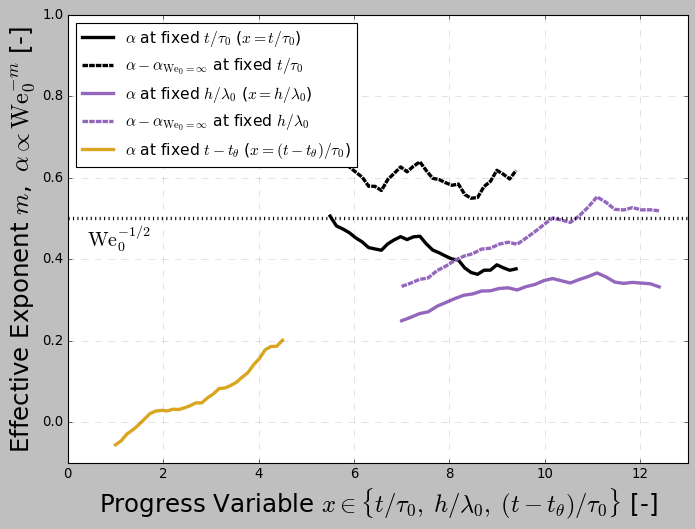

In [9]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
lw = np.log([50, 100, 200])
def slope_m(vals):
    return -np.polyfit(lw, np.log(vals), 1)[0]
def a_at_h(k, hval):
    t, a, h = alpha_of_h(k); m = t > t_peak[k]
    return np.interp(hval, h[m], a[m])
ts = np.linspace(5.5, 9.4, 30)
m_t = [slope_m([np.interp(s, *curve(A, k)) for k in FIN]) for s in ts]
m_tex = [slope_m([np.interp(s, *curve(A, k)) - np.interp(s, *curve(A, 'We_inf')) for k in FIN]) for s in ts]
hs = np.linspace(7.0, 12.4, 30)
m_h = [slope_m([a_at_h(k, x_) for k in FIN]) for x_ in hs]
m_hex = [slope_m([a_at_h(k, x_) - np.interp(x_, hi[mi], ai[mi]) for k in FIN]) for x_ in hs]
lags = np.linspace(1.0, 4.5, 30)
m_l = [slope_m([np.interp(T_THETA[k] + l, *curve(A, k)) for k in FIN]) for l in lags]
ax.plot(ts, m_t, lw=3, color='black', label=r'$\alpha$ at fixed $t/\tau_0$ ($x = t/\tau_0$)')
ax.plot(ts, m_tex, lw=3, color='black', linestyle=(0, (5, 1)),
        label=r'$\alpha-\alpha_{\mathrm{We}_0=\infty}$ at fixed $t/\tau_0$')
ax.plot(hs, m_h, lw=3, color='tab:purple', label=r'$\alpha$ at fixed $h/\lambda_0$ ($x = h/\lambda_0$)')
ax.plot(hs, m_hex, lw=3, color='tab:purple', linestyle=(0, (5, 1)),
        label=r'$\alpha-\alpha_{\mathrm{We}_0=\infty}$ at fixed $h/\lambda_0$')
ax.plot(lags, m_l, lw=3, color='goldenrod', label=r'$\alpha$ at fixed $t-t_\theta$ ($x = (t-t_\theta)/\tau_0$)')
ax.axhline(0.5, color='black', lw=3, linestyle=':')
ax.text(0.4, 0.43, r'$\mathrm{We}_0^{-1/2}$', fontsize=18, bbox=BOX)
ax.set_xlabel(r'Progress Variable $x \in \{t/\tau_0,\; h/\lambda_0,\; (t - t_\theta)/\tau_0\}$ [-]', fontsize=22)
ax.set_ylabel(r'Effective Exponent $m$, $\;\alpha \propto \mathrm{We}_0^{-m}$ [-]', fontsize=22)
ax.set_xlim(0, 13); ax.set_ylim(-0.1, 1.0)
finish(ax, 'fig_We_exponent', legend_loc='upper left', fontsize=14)

In [10]:
# table S2 (comparison at fixed time) and the coefficient K in alpha = alpha_inf + K We0^(-1/2) at each time
for s in [6.0, 6.5, 7.5, 8.5, 9.4]:
    v = {k: np.interp(s, *curve(A, k)) for k in WE}
    xw = np.array([WE[k] ** -0.5 if np.isfinite(WE[k]) else 0.0 for k in WE])
    p = np.polyfit(xw, np.array([v[k] for k in WE]), 1)
    r = v['We50'] / v['We200']
    print(f't/tau0 = {s}: alpha(50)/alpha(200) = {r:.2f} -> We0^-{np.log(r)/np.log(4):.2f};  '
          f'alpha = {p[1]:.4f} + {p[0]:.3f} We0^-1/2')

t/tau0 = 6.0: alpha(50)/alpha(200) = 1.89 -> We0^-0.46;  alpha = 0.0351 + 1.227 We0^-1/2
t/tau0 = 6.5: alpha(50)/alpha(200) = 1.80 -> We0^-0.43;  alpha = 0.0333 + 1.077 We0^-1/2
t/tau0 = 7.5: alpha(50)/alpha(200) = 1.84 -> We0^-0.44;  alpha = 0.0301 + 0.897 We0^-1/2
t/tau0 = 8.5: alpha(50)/alpha(200) = 1.66 -> We0^-0.37;  alpha = 0.0333 + 0.708 We0^-1/2
t/tau0 = 9.4: alpha(50)/alpha(200) = 1.68 -> We0^-0.38;  alpha = 0.0343 + 0.623 We0^-1/2


## 5. Supplementary figure S1: Hinze scale

The Hinze scale $\ell_H$ of `hinze_scale.csv` (in metres) relative to the capillary length
$\ell_\sigma = \lambda_0 (2 \mathrm{A_t} \mathrm{We}_0)^{-1/2}$, against $h/\ell_\sigma$ after the transition, with
$\lambda_0 = L/k_{\max} \approx 1.02$ cm and grid spacing $\Delta x \approx 0.114$ cm. $K_H$ is fitted with the slope
$-1/5$ for $t \ge 6\tau_0$.

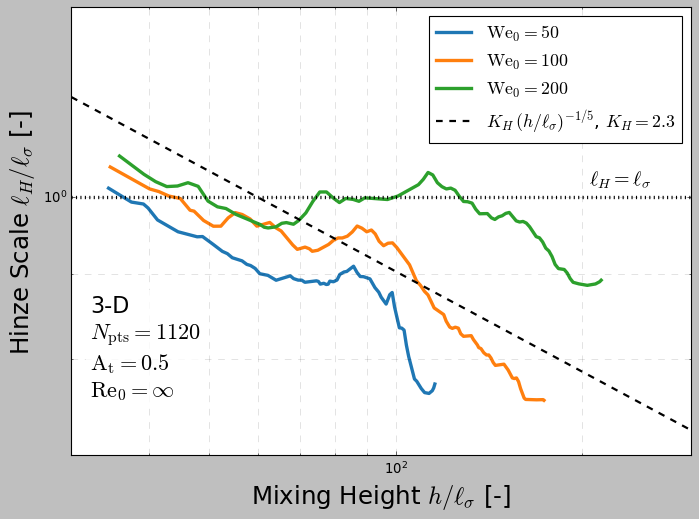

K_H fitted (t >= 6 tau0, slope -1/5): 2.27;  K_H^5 = 60
We50: t = 9.4: l_H = 1.20 mm, l_H/l_sigma = 0.83, l_H/dx = 1.05, h/l_sigma = 103, K_H = 2.10, d ln l_H/d ln h (6..9.4) = -0.11
We100: t = 9.4: l_H = 0.78 mm, l_H/l_sigma = 0.77, l_H/dx = 0.69, h/l_sigma = 159, K_H = 2.11, d ln l_H/d ln h (6..9.4) = -0.35
We200: t = 9.4: l_H = 0.64 mm, l_H/l_sigma = 0.89, l_H/dx = 0.56, h/l_sigma = 215, K_H = 2.61, d ln l_H/d ln h (6..9.4) = -0.25
l_H ~ We0^-0.45 at t = 9.4 tau0 (prediction at fixed h: We0^-0.6)


In [11]:
ls_over_l0 = {k: (2 * AT * WE[k]) ** -0.5 for k in FIN}
plt.figure(figsize=(10, 7)); ax = plt.gca()
fit_x, fit_y = [], []
for k in FIN:
    t, lh = curve(HINZE, k)
    m = t >= T_THETA[k]                                   # after the transition
    h = np.interp(t[m], *curve(H, k))                     # h/lambda0
    x = h / ls_over_l0[k]                                 # h/l_sigma
    y = lh[m] / LAMBDA0 / ls_over_l0[k]                   # l_H/l_sigma
    ax.plot(x, y, lw=3, color=COLORS[k], label=LABELS[k])
    late = t[m] >= 6.0
    fit_x += list(x[late]); fit_y += list(y[late])
fit_x, fit_y = np.array(fit_x), np.array(fit_y)
KH = float(np.exp(np.mean(np.log(fit_y) + 0.2 * np.log(fit_x))))     # slope fixed at -1/5
xs = np.logspace(np.log10(30), np.log10(300), 50)
ax.plot(xs, KH * xs ** -0.2, color='black', lw=2, linestyle='--', label=rf'$K_H\,(h/\ell_\sigma)^{{-1/5}}$, $K_H = {KH:.1f}$')
ax.axhline(1.0, color='black', lw=3, linestyle=':')
ax.text(230, 1.01, r'$\ell_H = \ell_\sigma$', fontsize=18, ha='center', va='bottom', bbox=BOX)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'Mixing Height $h/\ell_\sigma$ [-]', fontsize=22)
ax.set_ylabel(r'Hinze Scale $\ell_H/\ell_\sigma$ [-]', fontsize=22)
ax.set_xlim(30, 300); ax.set_ylim(0.7, 1.3)
text_box(ax, loc=(0.03, 0.36))
finish(ax, 'fig_hinze_ratio', legend_loc='upper right')

print(f'K_H fitted (t >= 6 tau0, slope -1/5): {KH:.2f};  K_H^5 = {KH ** 5:.0f}')
for k in FIN:
    t9 = min(9.4, curve(HINZE, k)[0].max())
    lh = np.interp(t9, *curve(HINZE, k)); h = np.interp(t9, *curve(H, k))
    ls = LAMBDA0 * ls_over_l0[k]
    kh = (lh / (h * LAMBDA0)) / (ls / (h * LAMBDA0)) ** 1.2
    ts = np.linspace(6.0, t9, 20)
    sl = np.polyfit(np.log(np.interp(ts, *curve(H, k))), np.log(np.interp(ts, *curve(HINZE, k))), 1)[0]
    print(f'{k}: t = {t9:.1f}: l_H = {lh * 1e3:.2f} mm, l_H/l_sigma = {lh / ls:.2f}, l_H/dx = {lh / DX:.2f}, '
          f'h/l_sigma = {h / ls_over_l0[k]:.0f}, K_H = {kh:.2f}, d ln l_H/d ln h (6..9.4) = {sl:+.2f}')
l50, l200 = (np.interp(9.4, *curve(HINZE, k)) for k in ('We50', 'We200'))
print(f'l_H ~ We0^-{np.log(l50 / l200) / np.log(4):.2f} at t = 9.4 tau0 (prediction at fixed h: We0^-0.6)')

## 6. Supplementary figure S4: transition

(*a*) The transition time, as the time $t_\theta$ of maximum $d\overline{\theta}/dt$ (the markers in the mixing-width
figure) or the time of peak $\alpha$, against $1/\mathrm{We}_0$, with linear fits. (*b*) $\alpha$ against time since
transition.

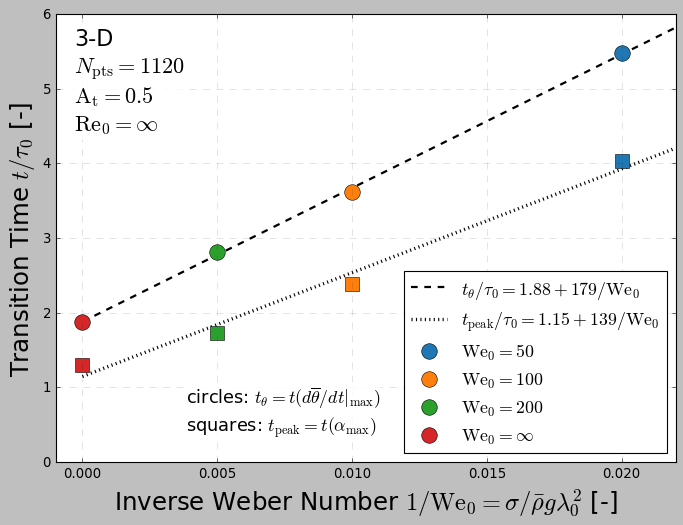

t_theta fit: [179.02531429   1.878986  ] rms 0.02992028449540059
t_peak  fit: [138.95954286   1.145574  ] rms 0.1344769063392351


In [12]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
x = np.array([1 / WE[k] if np.isfinite(WE[k]) else 0.0 for k in WE])
ytheta = np.array([T_THETA[k] for k in WE]); ypeak = np.array([t_peak[k] for k in WE])
pt = np.polyfit(x, ytheta, 1); pp = np.polyfit(x, ypeak, 1)
xx = np.linspace(0, 0.022, 50)
ax.plot(xx, np.polyval(pt, xx), color='black', lw=2, linestyle='--',
        label=rf'$t_\theta/\tau_0 = {pt[1]:.2f} + {pt[0]:.0f}/\mathrm{{We}}_0$')
ax.plot(xx, np.polyval(pp, xx), color='black', lw=3, linestyle=':',
        label=rf'$t_\mathrm{{peak}}/\tau_0 = {pp[1]:.2f} + {pp[0]:.0f}/\mathrm{{We}}_0$')
for i, k in enumerate(WE):
    ax.plot(x[i], ytheta[i], 'o', ms=14, color=COLORS[k], mec='black', label=LABELS[k])
    ax.plot(x[i], ypeak[i], 's', ms=12, color=COLORS[k], mec='black')
ax.set_xlabel(r'Inverse Weber Number $1/\mathrm{We}_0 = \sigma / \bar{\rho} g \lambda_0^2$ [-]', fontsize=22)
ax.set_ylabel(r'Transition Time $t/\tau_0$ [-]', fontsize=22)
ax.set_xlim(-0.001, 0.022); ax.set_ylim(0, 6)
ax.text(0.21, 0.07, r'circles: $t_\theta = t(d\overline{\theta}/dt|_\mathrm{max})$' + '\n' +
        r'squares: $t_\mathrm{peak} = t(\alpha_\mathrm{max})$', transform=ax.transAxes, fontsize=16, bbox=BOX)
text_box(ax, loc=(0.03, 0.97))
finish(ax, 'fig_transition_time', legend_loc='lower right')
print('t_theta fit:', pt, 'rms', np.sqrt(np.mean((np.polyval(pt, x) - ytheta) ** 2)))
print('t_peak  fit:', pp, 'rms', np.sqrt(np.mean((np.polyval(pp, x) - ypeak) ** 2)))

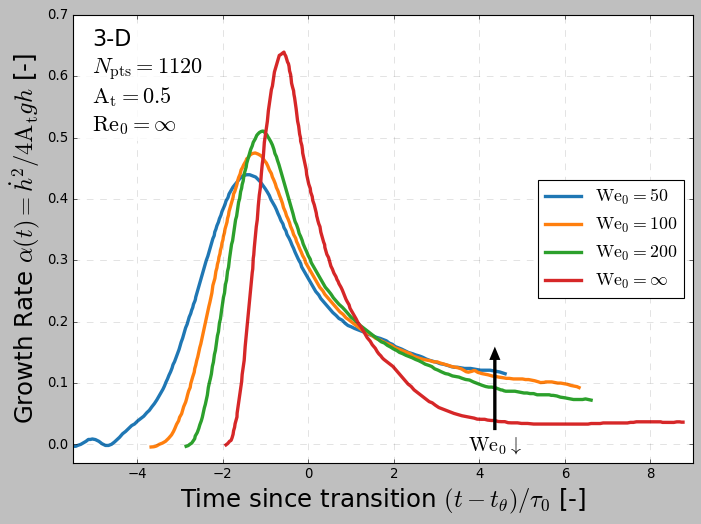

(t - t_theta)/tau0 = 2: max/min over We0 = 1.04, finite/infinite = 1.26
(t - t_theta)/tau0 = 3: max/min over We0 = 1.10, finite/infinite = 2.08
(t - t_theta)/tau0 = 4: max/min over We0 = 1.24, finite/infinite = 2.72
(t - t_theta)/tau0 = 4.5: max/min over We0 = 1.32, finite/infinite = 2.83


In [13]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
for k in WE:
    t, a = curve(A, k)
    ax.plot(t - T_THETA[k], a, lw=3, color=COLORS[k], label=LABELS[k])
ax.set_xlabel(r'Time since transition $(t - t_\theta)/\tau_0$ [-]', fontsize=22)
ax.set_ylabel(r'Growth Rate $\alpha(t) = \dot{h}^2 / 4 \mathrm{A_t} g h$ [-]', fontsize=22)
ax.set_xlim(-5.5, 9); ax.set_ylim(-0.03, 0.7)
ax.annotate(r'$\mathrm{We}_0 \downarrow$', xy=(0.68, 0.27), xytext=(0.68, 0.015), xycoords='axes fraction',
            textcoords='axes fraction', ha='center', va='bottom', fontsize=18, arrowprops=ARROW, bbox=BOX)
text_box(ax, loc=(0.03, 0.97))
finish(ax, 'fig_alpha_transition', legend_loc='center right')
for lag in [2, 3, 4, 4.5]:
    v = [np.interp(T_THETA[k] + lag, *curve(A, k)) for k in FIN]
    vi = np.interp(T_THETA['We_inf'] + lag, *curve(A, 'We_inf'))
    print(f'(t - t_theta)/tau0 = {lag}: max/min over We0 = {max(v)/min(v):.2f}, finite/infinite = {np.mean(v)/vi:.2f}')

## 7. Supplementary figure S5 and table S3: mid-plane mass flux

The plotted scaling ratio of the simulations uses the half-width $h/2$; for the full width
$h = 6 \int \overline{V}(1 - \overline{V})\,dz$, the shape factor is $R_f = \Delta\rho\,\dot h/|\overline{\rho' w'}|_0 = 2 \times$ (scaling ratio).
Table S3 applies $\alpha = (R_f^2/16)\, C_r^2 (1 - \theta_0)\, \mathrm{Fr}_0^2$, averaged over $8 \le t/\tau_0 \le 9.4$, with
$1 - \theta_0 = (2 \rho'_\mathrm{rms}/\Delta\rho)^2$ on the mid-plane.

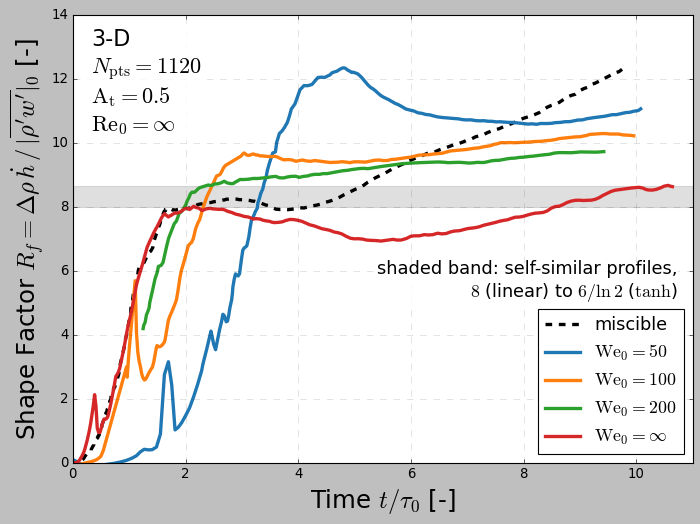

We50: mean R_f over 8 <= t/tau0 <= 9.4 = 10.66
We100: mean R_f over 8 <= t/tau0 <= 9.4 = 10.15
We200: mean R_f over 8 <= t/tau0 <= 9.4 = 9.67
We_inf: mean R_f over 8 <= t/tau0 <= 9.4 = 8.04
miscible: mean R_f over 8 <= t/tau0 <= 9.4 = 11.38


In [14]:
plt.figure(figsize=(10, 7)); ax = plt.gca()
ax.axhspan(8.0, 6 / np.log(2), color='gray', alpha=0.25)
ax.text(0.975, 0.37, 'shaded band: self-similar profiles,\n' + r'$8$ (linear) to $6/\ln 2$ ($\mathrm{tanh}$)', ha='right', transform=ax.transAxes, fontsize=16, bbox=BOX)
t, r = curve(SR, 'miscible')
ax.plot(t, 2 * np.array(r), lw=3, color='black', linestyle='--', label='miscible')
for k in WE:
    t, r = curve(SR, k)
    ax.plot(t, 2 * np.array(r), lw=3, color=COLORS[k], label=LABELS[k])
ax.set_xlabel(r'Time $t/\tau_0$ [-]', fontsize=22)
ax.set_ylabel(r'Shape Factor $R_f = \Delta\rho\,\dot{h}\,/\,|\overline{\rho^\prime w^\prime}|_0$ [-]', fontsize=22)
ax.set_xlim(0, 11); ax.set_ylim(0, 14)
text_box(ax, loc=(0.03, 0.97))
finish(ax, 'fig_Rf_time', legend_loc='lower right')
for k in list(WE) + ['miscible']:
    x, y = curve(SR, k); m = (x >= 8) & (x <= 9.4)
    print(f'{k}: mean R_f over 8 <= t/tau0 <= 9.4 = {2 * np.mean(y[m]):.2f}')

In [15]:
# table S3: decomposition alpha = (R_f^2/16) C_r^2 (1 - theta_0) Fr_0^2, averaged over 8 <= t/tau0 <= 9.4
def late_mean(c, k, a=8.0, b=9.4):
    x, y = curve(c, k); m = (x >= a) & (x <= b)
    return float(np.mean(y[m]))

rows = {}
for k in list(WE) + ['miscible']:
    al = late_mean(A, k)
    Rf = 2 * late_mean(SR, k)
    pur = (2 * late_mean(RHO, k)) ** 2                # 1 - theta_0
    rows[k] = dict(alpha=al, Rf=Rf, theta0=1 - pur, pur=pur, q=16 * al / (Rf ** 2 * pur))   # q = C_r^2 Fr_0^2
ref = rows['We_inf']
print(f"{'case':9s} {'alpha':>6s} {'R_f':>5s} {'theta0':>6s} {'Cr2Fr2':>7s} {'CrFr':>6s} | ratio to We0 = inf: "
      f"{'alpha':>5s} {'R_f^2':>5s} {'1-th0':>5s} {'Cr2Fr2':>6s} {'(1-th0)^3/2':>11s}")
for k, r in rows.items():
    ra, rR, rp, rq = r['alpha'] / ref['alpha'], (r['Rf'] / ref['Rf']) ** 2, r['pur'] / ref['pur'], r['q'] / ref['q']
    print(f"{k:9s} {r['alpha']:6.3f} {r['Rf']:5.1f} {r['theta0']:6.2f} {r['q']:7.4f} {r['q'] ** 0.5:6.3f} | "
          f"{'':20s}{ra:5.2f} {rR:5.2f} {rp:5.2f} {rq:6.2f} {rp ** 1.5:11.2f}")

case       alpha   R_f theta0  Cr2Fr2   CrFr | ratio to We0 = inf: alpha R_f^2 1-th0 Cr2Fr2 (1-th0)^3/2
We50       0.132  10.7   0.10  0.0206  0.144 |                      3.84  1.76  1.49   1.46        1.82
We100      0.105  10.2   0.13  0.0189  0.138 |                      3.07  1.60  1.43   1.34        1.72
We200      0.078   9.7   0.19  0.0166  0.129 |                      2.27  1.45  1.34   1.17        1.54
We_inf     0.034   8.0   0.40  0.0141  0.119 |                      1.00  1.00  1.00   1.00        1.00
miscible   0.023  11.4   0.86  0.0198  0.141 |                      0.66  2.00  0.24   1.40        0.11
